# VS code cũng đẹp mà
Tui yêu cái đẹp, thấy cái gì đẹp là tui lưu lại hết à
Tui muốn sản phẩm mk làm ra có sự chỉnh chu, áp dụng được vào thực tiễn, thực sự có ích cho đời

In [3]:
# import libraries 

import numpy as np
import pandas as pd
import unicodedata
import re


#Vẽ biểu đồ
import matplotlib.pyplot as plt 

# Vẽ biểu đồ nhiệt
import seaborn as sns

from collections import Counter

# 1. ETL Basic Statisctic

In [3]:
# review file data
filename = r"E:\Chuyển từ download sang\A Học tập Bách Khoa\ĐA2\Đồ án 2 _ 2025\Project_full\Crawl_job\Data_raw\data_topcv.csv"

df=pd.read_csv(filename)
df

,index,job_link,keyword,title,company_name,location,salary,date_posted,deadline_date,company_field,job_type,job_level,experience,education,hire_number,job_expertise,description,requirements,benefits
0,1,https://www.topcv.vn/viec-lam/chuyen-vien-du-a...,Data Analyst,Chuyên Viên Dự Án Lưu Trữ & Số Hóa Tài Liệu,Viện Nghiên cứu Quản Lý Hành Chính,Hồ Chí Minh,Từ 15 triệu,2026-04-13,13/05/2026,Giáo dục / Đào tạo,Toàn thời gian,Nhân viên,Không yêu cầu,Trung cấp trở lên,10 người,"Phân tích dữ liệu, Nhân sự","Thực hiện chỉnh lý, sắp xếp, phân loại tài liệ...",Tốt nghiệp từ Trung cấp trở lên (ưu tiên các n...,Thời gian thử việc và đào tạo: 03 tháng (được ...
1,2,https://www.topcv.vn/viec-lam/da-de-data-analy...,Data Analyst,DA/DE - Data Analyst / Data Engineer Thu Nhập ...,Công ty TNHH thương mại và XNK Winki Group,Hà Nội,18 - 25 triệu,2026-04-11,30/06/2026,Bán lẻ - Hàng tiêu dùng - FMCG,Toàn thời gian,Nhân viên,1 năm,Cao Đẳng trở lên,2 người,"Data Analyst, IT - Phần mềm, Thương mại điện t...",Thu thập & Xây dựng luồng dữ liệu (ETL / Data ...,Kinh nghiệm: 1 3 năm ở vị trí Data Analyst. Bắ...,Thu nhập: Lương cơ bản 15.000.000 25.000.000 V...
2,3,https://www.topcv.vn/viec-lam/business-analyst...,Data Analyst,Business Analyst ( BA - Chuyên Viên Phân Tích ...,Công ty TNHH thương mại và XNK Winki Group,Hà Nội,18 - 25 triệu,2026-04-11,30/06/2026,Bán lẻ - Hàng tiêu dùng - FMCG,Toàn thời gian,Nhân viên,1 năm,Cao Đẳng trở lên,2 người,"Data Analyst, Thương mại điện tử, IT - Phần mề...",Khảo sát & Phân tích nghiệp vụ (Requirement Ga...,Kinh nghiệm: Có từ 1 năm kinh nghiệm làm Busin...,"Thu nhập cốt lõi: Dải lương cơ bản 18,000,000 ..."
3,4,https://www.topcv.vn/viec-lam/chuyen-vien-phan...,Data Analyst,Chuyên Viên Phân Tích Dữ Liệu & AI Agent,Công ty Cổ phần Thương mại Dịch vụ 4B,Hồ Chí Minh,Thoả thuận,2026-04-08,08/05/2026,Dược phẩm / Y tế / Công nghệ sinh học,Toàn thời gian,Nhân viên,2 năm,Cao Đẳng trở lên,1 người,"Data Analyst, Chăm sóc sức khỏe / Làm đẹp, Y t...",Hệ thống Dữ liệu & Tự động hóa (40%) Kết nối đ...,"Hiểu biết sâu về cấu trúc dữ liệu, kho dữ liệu...",Thu nhập: Mức lương cạnh tranh theo năng lực (...
4,5,https://www.topcv.vn/viec-lam/product-builder-...,Data Analyst,Product Builder (Remote),CÔNG TY CỔ PHẦN KIMQ,Hồ Chí Minh,Thoả thuận,2026-04-07,07/05/2026,IT - Phần mềm,Toàn thời gian,Nhân viên,2 năm,Đại Học trở lên,2 người,Data Analyst,Trực tiếp xây dựng và phát triển sản phẩm bằng...,Có kinh nghiệm xây dựng sản phẩm bằng công cụ ...,Lương: thỏa thuận theo năng lực ứng viên Được ...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
784,785,https://www.topcv.vn/viec-lam/database-admin/2...,Database Administrator,Database Admin,Công ty cổ phần Hạ tầng Viễn thông CMC Telecom...,Hà Nội,Thoả thuận,2026-06-08,31/08/2026,Viễn thông,Làm việc tại văn phòng / Onsite,Nhân viên,Dưới 1 năm,Đại Học trở lên,2 người,Database Administrator (DBA),Đảm bảo vận hành ổn định hàng ngày các hệ quản...,– Có từ 6 tháng kinh nghiệm vận hành cơ sở dữ ...,"Đãi ngộ (lương, thưởng, review lương): – Mức l..."
785,786,https://www.topcv.vn/viec-lam/data-operations-...,Database Administrator,Data Operations Administrator,Công ty Cổ phần Phát triển Truyền thông Quảng ...,Hồ Chí Minh,8 - 12 triệu,2026-06-06,04/07/2026,Marketing / Truyền thông / Quảng cáo,Làm việc tại văn phòng / Onsite,Nhân viên,1 năm,Đại Học trở lên,1 người,"Database Administrator (DBA), Công nghệ kỹ thuật","Quản lý, kiểm tra và chuẩn hóa dữ liệu từ nhiề...","Cẩn thận, tư duy logic tốt và có trách nhiệm t...",Mức lương:8 12tr/tháng tùy theo năng lực. Phúc...
786,787,https://www.topcv.vn/viec-lam/database-adminis...,Database Administrator,Database Administrator,Công Ty TNHH LG CNS VIỆT NAM,Hà Nội,Thoả thuận,2026-06-06,03/07/2026,IT - Phần mềm,Làm việc tại văn phòng / Onsite,Nhân viên,3 năm,Đại Học trở lên,1 người,"Database Administrator (DBA), IT - Phần mềm, Đ...","Administer, operate, and optimize database sys...",Handson experience with at least two database ...,Attracti

## 1. ĐỔI TÊN CỘT

### 1.1 Thêm cột "source" cho data, mặc định `1` nghĩa là `topcv`

In [4]:
df['source'] = "3"

In [5]:
df.head(5)

,index,job_link,keyword,title,company_name,location,salary,date_posted,deadline_date,company_field,job_type,job_level,experience,education,hire_number,job_expertise,description,requirements,benefits,source
0,1,https://www.topcv.vn/viec-lam/chuyen-vien-du-a...,Data Analyst,Chuyên Viên Dự Án Lưu Trữ & Số Hóa Tài Liệu,Viện Nghiên cứu Quản Lý Hành Chính,Hồ Chí Minh,Từ 15 triệu,2026-04-13,13/05/2026,Giáo dục / Đào tạo,Toàn thời gian,Nhân viên,Không yêu cầu,Trung cấp trở lên,10 người,"Phân tích dữ liệu, Nhân sự","Thực hiện chỉnh lý, sắp xếp, phân loại tài liệ...",Tốt nghiệp từ Trung cấp trở lên (ưu tiên các n...,Thời gian thử việc và đào tạo: 03 tháng (được ...,3
1,2,https://www.topcv.vn/viec-lam/da-de-data-analy...,Data Analyst,DA/DE - Data Analyst / Data Engineer Thu Nhập ...,Công ty TNHH thương mại và XNK Winki Group,Hà Nội,18 - 25 triệu,2026-04-11,30/06/2026,Bán lẻ - Hàng tiêu dùng - FMCG,Toàn thời gian,Nhân viên,1 năm,Cao Đẳng trở lên,2 người,"Data Analyst, IT - Phần mềm, Thương mại điện t...",Thu thập & Xây dựng luồng dữ liệu (ETL / Data ...,Kinh nghiệm: 1 3 năm ở vị trí Data Analyst. Bắ...,Thu nhập: Lương cơ bản 15.000.000 25.000.000 V...,3
2,3,https://www.topcv.vn/viec-lam/business-analyst...,Data Analyst,Business Analyst ( BA - Chuyên Viên Phân Tích ...,Công ty TNHH thương mại và XNK Winki Group,Hà Nội,18 - 25 triệu,2026-04-11,30/06/2026,Bán lẻ - Hàng tiêu dùng - FMCG,Toàn thời gian,Nhân viên,1 năm,Cao Đẳng trở lên,2 người,"Data Analyst, Thương mại điện tử, IT - Phần mề...",Khảo sát & Phân tích nghiệp vụ (Requirement Ga...,Kinh nghiệm: Có từ 1 năm kinh nghiệm làm Busin...,"Thu nhập cốt lõi: Dải lương cơ bản 18,000,000 ...",3
3,4,https://www.topcv.vn/viec-lam/chuyen-vien-phan...,Data Analyst,Chuyên Viên Phân Tích Dữ Liệu & AI Agent,Công ty Cổ phần Thương mại Dịch vụ 4B,Hồ Chí Minh,Thoả thuận,2026-04-08,08/05/2026,Dược phẩm / Y tế / Công nghệ sinh học,Toàn thời gian,Nhân viên,2 năm,Cao Đẳng trở lên,1 người,"Data Analyst, Chăm sóc sức khỏe / Làm đẹp, Y t...",Hệ thống Dữ liệu & Tự động hóa (40%) Kết nối đ...,"Hiểu biết sâu về cấu trúc dữ liệu, kho dữ liệu...",Thu nhập: Mức lương cạnh tranh theo năng lực (...,3
4,5,https://www.topcv.vn/viec-lam/product-builder-...,Data Analyst,Product Builder (Remote),CÔNG TY CỔ PHẦN KIMQ,Hồ Chí Minh,Thoả thuận,2026-04-07,07/05/2026,IT - Phần mềm,Toàn thời gian,Nhân viên,2 năm,Đại Học trở lên,2 người,Data Analyst,Trực tiếp xây dựng và phát triển sản phẩm bằng...,Có kinh nghiệm xây dựng sản phẩm bằng công cụ ...,Lương: thỏa thuận theo năng lực ứng viên Được ...,3


### 1.2 Đổi tên 1 loạt các cột khác

In [6]:
df = df.rename(columns={
    'job_link': 'job_url',
    'title': 'job_title'
})


In [7]:
df.head(5)

,index,job_url,keyword,job_title,company_name,location,salary,date_posted,deadline_date,company_field,job_type,job_level,experience,education,hire_number,job_expertise,description,requirements,benefits,source
0,1,https://www.topcv.vn/viec-lam/chuyen-vien-du-a...,Data Analyst,Chuyên Viên Dự Án Lưu Trữ & Số Hóa Tài Liệu,Viện Nghiên cứu Quản Lý Hành Chính,Hồ Chí Minh,Từ 15 triệu,2026-04-13,13/05/2026,Giáo dục / Đào tạo,Toàn thời gian,Nhân viên,Không yêu cầu,Trung cấp trở lên,10 người,"Phân tích dữ liệu, Nhân sự","Thực hiện chỉnh lý, sắp xếp, phân loại tài liệ...",Tốt nghiệp từ Trung cấp trở lên (ưu tiên các n...,Thời gian thử việc và đào tạo: 03 tháng (được ...,3
1,2,https://www.topcv.vn/viec-lam/da-de-data-analy...,Data Analyst,DA/DE - Data Analyst / Data Engineer Thu Nhập ...,Công ty TNHH thương mại và XNK Winki Group,Hà Nội,18 - 25 triệu,2026-04-11,30/06/2026,Bán lẻ - Hàng tiêu dùng - FMCG,Toàn thời gian,Nhân viên,1 năm,Cao Đẳng trở lên,2 người,"Data Analyst, IT - Phần mềm, Thương mại điện t...",Thu thập & Xây dựng luồng dữ liệu (ETL / Data ...,Kinh nghiệm: 1 3 năm ở vị trí Data Analyst. Bắ...,Thu nhập: Lương cơ bản 15.000.000 25.000.000 V...,3
2,3,https://www.topcv.vn/viec-lam/business-analyst...,Data Analyst,Business Analyst ( BA - Chuyên Viên Phân Tích ...,Công ty TNHH thương mại và XNK Winki Group,Hà Nội,18 - 25 triệu,2026-04-11,30/06/2026,Bán lẻ - Hàng tiêu dùng - FMCG,Toàn thời gian,Nhân viên,1 năm,Cao Đẳng trở lên,2 người,"Data Analyst, Thương mại điện tử, IT - Phần mề...",Khảo sát & Phân tích nghiệp vụ (Requirement Ga...,Kinh nghiệm: Có từ 1 năm kinh nghiệm làm Busin...,"Thu nhập cốt lõi: Dải lương cơ bản 18,000,000 ...",3
3,4,https://www.topcv.vn/viec-lam/chuyen-vien-phan...,Data Analyst,Chuyên Viên Phân Tích Dữ Liệu & AI Agent,Công ty Cổ phần Thương mại Dịch vụ 4B,Hồ Chí Minh,Thoả thuận,2026-04-08,08/05/2026,Dược phẩm / Y tế / Công nghệ sinh học,Toàn thời gian,Nhân viên,2 năm,Cao Đẳng trở lên,1 người,"Data Analyst, Chăm sóc sức khỏe / Làm đẹp, Y t...",Hệ thống Dữ liệu & Tự động hóa (40%) Kết nối đ...,"Hiểu biết sâu về cấu trúc dữ liệu, kho dữ liệu...",Thu nhập: Mức lương cạnh tranh theo năng lực (...,3
4,5,https://www.topcv.vn/viec-lam/product-builder-...,Data Analyst,Product Builder (Remote),CÔNG TY CỔ PHẦN KIMQ,Hồ Chí Minh,Thoả thuận,2026-04-07,07/05/2026,IT - Phần mềm,Toàn thời gian,Nhân viên,2 năm,Đại Học trở lên,2 người,Data Analyst,Trực tiếp xây dựng và phát triển sản phẩm bằng...,Có kinh nghiệm xây dựng sản phẩm bằng công cụ ...,Lương: thỏa thuận theo năng lực ứng viên Được ...,3


In [8]:
## 2. SAVED lần 1
df.to_csv("data_topvc_1.csv", index=False, encoding="utf-8-sig")

### 1.3 Đổi tên lần cuối và xóa các cột phụ

In [5]:
# review file data
filename_4 = r"data_topcv_4.csv"

df=pd.read_csv(filename_4)
df

,index,job_url,keyword,job_title,company_name,location,salary,date_posted,deadline_date,company_field,...,hire_number,job_expertise,description,requirements,benefits,source,work_type,job_position,edu,mean_salary
0,1,https://www.topcv.vn/viec-lam/chuyen-vien-du-a...,Data Analyst,Chuyên Viên Dự Án Lưu Trữ & Số Hóa Tài Liệu,Viện Nghiên cứu Quản Lý Hành Chính,Hồ Chí Minh,Từ 15 triệu,2026-04-13,2026-05-13,Giáo dục / Đào tạo,...,10 người,"Phân tích dữ liệu, Nhân sự","Thực hiện chỉnh lý, sắp xếp, phân loại tài liệ...",Tốt nghiệp từ Trung cấp trở lên (ưu tiên các n...,Thời gian thử việc và đào tạo: 03 tháng (được ...,3,Full-time,Nhân viên,Trung cấp,15000000.0
1,2,https://www.topcv.vn/viec-lam/da-de-data-analy...,Data Analyst,DA/DE - Data Analyst / Data Engineer Thu Nhập ...,Công ty TNHH thương mại và XNK Winki Group,Hà Nội,18 - 25 triệu,2026-04-11,2026-06-30,Bán lẻ - Hàng tiêu dùng - FMCG,...,2 người,"Data Analyst, IT - Phần mềm, Thương mại điện t...",Thu thập & Xây dựng luồng dữ liệu (ETL / Data ...,Kinh nghiệm: 1 3 năm ở vị trí Data Analyst. Bắ...,Thu nhập: Lương cơ bản 15.000.000 25.000.000 V...,3,Full-time,Nhân viên,Cao đẳng,21500000.0
2,3,https://www.topcv.vn/viec-lam/business-analyst...,Data Analyst,Business Analyst ( BA - Chuyên Viên Phân Tích ...,Công ty TNHH thương mại và XNK Winki Group,Hà Nội,18 - 25 triệu,2026-04-11,2026-06-30,Bán lẻ - Hàng tiêu dùng - FMCG,...,2 người,"Data Analyst, Thương mại điện tử, IT - Phần mề...",Khảo sát & Phân tích nghiệp vụ (Requirement Ga...,Kinh nghiệm: Có từ 1 năm kinh nghiệm làm Busin...,"Thu nhập cốt lõi: Dải lương cơ bản 18,000,000 ...",3,Full-time,Nhân viên,Cao đẳng,21500000.0
3,4,https://www.topcv.vn/viec-lam/chuyen-vien-phan...,Data Analyst,Chuyên Viên Phân Tích Dữ Liệu & AI Agent,Công ty Cổ phần Thương mại Dịch vụ 4B,Hồ Chí Minh,Thoả thuận,2026-04-08,2026-05-08,Dược phẩm / Y tế / Công nghệ sinh học,...,1 người,"Data Analyst, Chăm sóc sức khỏe / Làm đẹp, Y t...",Hệ thống Dữ liệu & Tự động hóa (40%) Kết nối đ...,"Hiểu biết sâu về cấu trúc dữ liệu, kho dữ liệu...",Thu nhập: Mức lương cạnh tranh theo năng lực (...,3,Full-time,Nhân viên,Cao đẳng,NaN
4,5,https://www.topcv.vn/viec-lam/product-builder-...,Data Analyst,Product Builder (Remote),CÔNG TY CỔ PHẦN KIMQ,Hồ Chí Minh,Thoả thuận,2026-04-07,2026-05-07,IT - Phần mềm,...,2 người,Data Analyst,Trực tiếp xây dựng và phát triển sản phẩm bằng...,Có kinh nghiệm xây dựng sản phẩm bằng công cụ ...,Lương: thỏa thuận theo năng lực ứng viên Được ...,3,Full-time,Nhân viên,Đại học,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
784,785,https://www.topcv.vn/viec-lam/database-admin/2...,Database Administrator,Database Admin,Công ty cổ phần Hạ tầng Viễn thông CMC Telecom...,Hà Nội,Thoả thuận,2026-06-08,2026-08-31,Viễn thông,...,2 người,Database Administrator (DBA),Đảm bảo vận hành ổn định hàng ngày các hệ quản...,– Có từ 6 tháng kinh nghiệm vận hành cơ sở dữ ...,"Đãi ngộ (lương, thưởng, review lương): – Mức l...",3,Full-time,Nhân viên,Đại học,NaN
785,786,https://www.topcv.vn/viec-lam/data-operations-...,Database Administrator,Data Operations Administrator,Công ty Cổ phần Phát triển Truyền thông Quảng ...,Hồ Chí Minh,8 - 12 triệu,2026-06-06,2026-07-04,Marketing / Truyền thông / Quảng cáo,...,1 người,"Database Administrator (DBA), Công nghệ kỹ thuật","Quản lý, kiểm tra và chuẩn hóa dữ liệu từ nhiề...","Cẩn thận, tư duy logic tốt và có trách nhiệm t...",Mức lương:8 12tr/tháng tùy theo năng lực. Phúc...,3,Full-time,Nhân viên,Đại học,10000000.0
786,787,https://www.topcv.vn/viec-lam/database-adminis...,Database Administrator,Database Administrator,Công Ty TNHH LG CNS VIỆT NAM,Hà Nội,Thoả thuận,2026-06-06,2026-07-03,IT - Phần mềm,...,1 người,"Database Administrator (DBA), IT - Phần mềm, Đ...","Administer, operate, and optimize database sys...",Handson experience with at least two database ...,Attractive salary and bonus will be discussed ...,3,Full-time,Nhân viên,Đại học,NaN
787,788,https://www.topcv.vn/viec-lam/dba-tea

In [6]:
# Đổi tên các cột để đồng bộ trước khi ghép file
df = df.rename(columns={
    'job_expertise' : 'category',
    'experience'    : 'min_experience',
    'deadline_date' : 'date_deadline',
    'keyword'       : 'search_keyword'
})


# Xóa các cột không cần thiết
df = df.drop(columns=['hire_number'])

df

,index,job_url,search_keyword,job_title,company_name,location,salary,date_posted,date_deadline,company_field,min_experience,category,description,requirements,benefits,source,work_type,job_position,edu,mean_salary
0,1,https://www.topcv.vn/viec-lam/chuyen-vien-du-a...,Data Analyst,Chuyên Viên Dự Án Lưu Trữ & Số Hóa Tài Liệu,Viện Nghiên cứu Quản Lý Hành Chính,Hồ Chí Minh,Từ 15 triệu,2026-04-13,2026-05-13,Giáo dục / Đào tạo,0.0,"Phân tích dữ liệu, Nhân sự","Thực hiện chỉnh lý, sắp xếp, phân loại tài liệ...",Tốt nghiệp từ Trung cấp trở lên (ưu tiên các n...,Thời gian thử việc và đào tạo: 03 tháng (được ...,3,Full-time,Nhân viên,Trung cấp,15000000.0
1,2,https://www.topcv.vn/viec-lam/da-de-data-analy...,Data Analyst,DA/DE - Data Analyst / Data Engineer Thu Nhập ...,Công ty TNHH thương mại và XNK Winki Group,Hà Nội,18 - 25 triệu,2026-04-11,2026-06-30,Bán lẻ - Hàng tiêu dùng - FMCG,1.0,"Data Analyst, IT - Phần mềm, Thương mại điện t...",Thu thập & Xây dựng luồng dữ liệu (ETL / Data ...,Kinh nghiệm: 1 3 năm ở vị trí Data Analyst. Bắ...,Thu nhập: Lương cơ bản 15.000.000 25.000.000 V...,3,Full-time,Nhân viên,Cao đẳng,21500000.0
2,3,https://www.topcv.vn/viec-lam/business-analyst...,Data Analyst,Business Analyst ( BA - Chuyên Viên Phân Tích ...,Công ty TNHH thương mại và XNK Winki Group,Hà Nội,18 - 25 triệu,2026-04-11,2026-06-30,Bán lẻ - Hàng tiêu dùng - FMCG,1.0,"Data Analyst, Thương mại điện tử, IT - Phần mề...",Khảo sát & Phân tích nghiệp vụ (Requirement Ga...,Kinh nghiệm: Có từ 1 năm kinh nghiệm làm Busin...,"Thu nhập cốt lõi: Dải lương cơ bản 18,000,000 ...",3,Full-time,Nhân viên,Cao đẳng,21500000.0
3,4,https://www.topcv.vn/viec-lam/chuyen-vien-phan...,Data Analyst,Chuyên Viên Phân Tích Dữ Liệu & AI Agent,Công ty Cổ phần Thương mại Dịch vụ 4B,Hồ Chí Minh,Thoả thuận,2026-04-08,2026-05-08,Dược phẩm / Y tế / Công nghệ sinh học,2.0,"Data Analyst, Chăm sóc sức khỏe / Làm đẹp, Y t...",Hệ thống Dữ liệu & Tự động hóa (40%) Kết nối đ...,"Hiểu biết sâu về cấu trúc dữ liệu, kho dữ liệu...",Thu nhập: Mức lương cạnh tranh theo năng lực (...,3,Full-time,Nhân viên,Cao đẳng,NaN
4,5,https://www.topcv.vn/viec-lam/product-builder-...,Data Analyst,Product Builder (Remote),CÔNG TY CỔ PHẦN KIMQ,Hồ Chí Minh,Thoả thuận,2026-04-07,2026-05-07,IT - Phần mềm,2.0,Data Analyst,Trực tiếp xây dựng và phát triển sản phẩm bằng...,Có kinh nghiệm xây dựng sản phẩm bằng công cụ ...,Lương: thỏa thuận theo năng lực ứng viên Được ...,3,Full-time,Nhân viên,Đại học,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
784,785,https://www.topcv.vn/viec-lam/database-admin/2...,Database Administrator,Database Admin,Công ty cổ phần Hạ tầng Viễn thông CMC Telecom...,Hà Nội,Thoả thuận,2026-06-08,2026-08-31,Viễn thông,1.0,Database Administrator (DBA),Đảm bảo vận hành ổn định hàng ngày các hệ quản...,– Có từ 6 tháng kinh nghiệm vận hành cơ sở dữ ...,"Đãi ngộ (lương, thưởng, review lương): – Mức l...",3,Full-time,Nhân viên,Đại học,NaN
785,786,https://www.topcv.vn/viec-lam/data-operations-...,Database Administrator,Data Operations Administrator,Công ty Cổ phần Phát triển Truyền thông Quảng ...,Hồ Chí Minh,8 - 12 triệu,2026-06-06,2026-07-04,Marketing / Truyền thông / Quảng cáo,1.0,"Database Administrator (DBA), Công nghệ kỹ thuật","Quản lý, kiểm tra và chuẩn hóa dữ liệu từ nhiề...","Cẩn thận, tư duy logic tốt và có trách nhiệm t...",Mức lương:8 12tr/tháng tùy theo năng lực. Phúc...,3,Full-time,Nhân viên,Đại học,10000000.0
786,787,https://www.topcv.vn/viec-lam/database-adminis...,Database Administrator,Database Administrator,Công Ty TNHH LG CNS VIỆT NAM,Hà Nội,Thoả thuận,2026-06-06,2026-07-03,IT - Phần mềm,3.0,"Database Administrator (DBA), IT - Phần mềm, Đ...","Administer, operate, and optimize database sys...",Handson experience with at least two database ...,Attractive salary and bonus will be discussed ...,3,Full-time,Nhân viên,Đại học,NaN
787,788,https://www.topcv.vn/viec-lam/dba-team-lead/21...,Database Administrator,DBA Team Lead,Công Ty Tài Chính 

In [7]:
## 2. SAVED lần 5
## Lần cuối nha
df.to_csv("data_topcv_5.csv", index=False, encoding="utf-8-sig")

# 2. ELT các cột

In [3]:
# review file data
filename = r"data_topvc_1.csv"

df=pd.read_csv(filename)
df

,index,job_url,keyword,job_title,company_name,location,salary,date_posted,deadline_date,company_field,job_type,job_level,experience,education,hire_number,job_expertise,description,requirements,benefits,source
0,1,https://www.topcv.vn/viec-lam/chuyen-vien-du-a...,Data Analyst,Chuyên Viên Dự Án Lưu Trữ & Số Hóa Tài Liệu,Viện Nghiên cứu Quản Lý Hành Chính,Hồ Chí Minh,Từ 15 triệu,2026-04-13,13/05/2026,Giáo dục / Đào tạo,Toàn thời gian,Nhân viên,Không yêu cầu,Trung cấp trở lên,10 người,"Phân tích dữ liệu, Nhân sự","Thực hiện chỉnh lý, sắp xếp, phân loại tài liệ...",Tốt nghiệp từ Trung cấp trở lên (ưu tiên các n...,Thời gian thử việc và đào tạo: 03 tháng (được ...,3
1,2,https://www.topcv.vn/viec-lam/da-de-data-analy...,Data Analyst,DA/DE - Data Analyst / Data Engineer Thu Nhập ...,Công ty TNHH thương mại và XNK Winki Group,Hà Nội,18 - 25 triệu,2026-04-11,30/06/2026,Bán lẻ - Hàng tiêu dùng - FMCG,Toàn thời gian,Nhân viên,1 năm,Cao Đẳng trở lên,2 người,"Data Analyst, IT - Phần mềm, Thương mại điện t...",Thu thập & Xây dựng luồng dữ liệu (ETL / Data ...,Kinh nghiệm: 1 3 năm ở vị trí Data Analyst. Bắ...,Thu nhập: Lương cơ bản 15.000.000 25.000.000 V...,3
2,3,https://www.topcv.vn/viec-lam/business-analyst...,Data Analyst,Business Analyst ( BA - Chuyên Viên Phân Tích ...,Công ty TNHH thương mại và XNK Winki Group,Hà Nội,18 - 25 triệu,2026-04-11,30/06/2026,Bán lẻ - Hàng tiêu dùng - FMCG,Toàn thời gian,Nhân viên,1 năm,Cao Đẳng trở lên,2 người,"Data Analyst, Thương mại điện tử, IT - Phần mề...",Khảo sát & Phân tích nghiệp vụ (Requirement Ga...,Kinh nghiệm: Có từ 1 năm kinh nghiệm làm Busin...,"Thu nhập cốt lõi: Dải lương cơ bản 18,000,000 ...",3
3,4,https://www.topcv.vn/viec-lam/chuyen-vien-phan...,Data Analyst,Chuyên Viên Phân Tích Dữ Liệu & AI Agent,Công ty Cổ phần Thương mại Dịch vụ 4B,Hồ Chí Minh,Thoả thuận,2026-04-08,08/05/2026,Dược phẩm / Y tế / Công nghệ sinh học,Toàn thời gian,Nhân viên,2 năm,Cao Đẳng trở lên,1 người,"Data Analyst, Chăm sóc sức khỏe / Làm đẹp, Y t...",Hệ thống Dữ liệu & Tự động hóa (40%) Kết nối đ...,"Hiểu biết sâu về cấu trúc dữ liệu, kho dữ liệu...",Thu nhập: Mức lương cạnh tranh theo năng lực (...,3
4,5,https://www.topcv.vn/viec-lam/product-builder-...,Data Analyst,Product Builder (Remote),CÔNG TY CỔ PHẦN KIMQ,Hồ Chí Minh,Thoả thuận,2026-04-07,07/05/2026,IT - Phần mềm,Toàn thời gian,Nhân viên,2 năm,Đại Học trở lên,2 người,Data Analyst,Trực tiếp xây dựng và phát triển sản phẩm bằng...,Có kinh nghiệm xây dựng sản phẩm bằng công cụ ...,Lương: thỏa thuận theo năng lực ứng viên Được ...,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
784,785,https://www.topcv.vn/viec-lam/database-admin/2...,Database Administrator,Database Admin,Công ty cổ phần Hạ tầng Viễn thông CMC Telecom...,Hà Nội,Thoả thuận,2026-06-08,31/08/2026,Viễn thông,Làm việc tại văn phòng / Onsite,Nhân viên,Dưới 1 năm,Đại Học trở lên,2 người,Database Administrator (DBA),Đảm bảo vận hành ổn định hàng ngày các hệ quản...,– Có từ 6 tháng kinh nghiệm vận hành cơ sở dữ ...,"Đãi ngộ (lương, thưởng, review lương): – Mức l...",3
785,786,https://www.topcv.vn/viec-lam/data-operations-...,Database Administrator,Data Operations Administrator,Công ty Cổ phần Phát triển Truyền thông Quảng ...,Hồ Chí Minh,8 - 12 triệu,2026-06-06,04/07/2026,Marketing / Truyền thông / Quảng cáo,Làm việc tại văn phòng / Onsite,Nhân viên,1 năm,Đại Học trở lên,1 người,"Database Administrator (DBA), Công nghệ kỹ thuật","Quản lý, kiểm tra và chuẩn hóa dữ liệu từ nhiề...","Cẩn thận, tư duy logic tốt và có trách nhiệm t...",Mức lương:8 12tr/tháng tùy theo năng lực. Phúc...,3
786,787,https://www.topcv.vn/viec-lam/database-adminis...,Database Administrator,Database Administrator,Công Ty TNHH LG CNS VIỆT NAM,Hà Nội,Thoả thuận,2026-06-06,03/07/2026,IT - Phần mềm,Làm việc tại văn phòng / Onsite,Nhân viên,3 năm,Đại Học trở lên,1 người,"Database Administrator (DBA), IT - Phần mềm, Đ...","Administer, operate, and optimize database sys...",Handson experience with at lea

## 2.1. Cột hình thức làm việc

In [5]:
df['job_type'].value_counts()

job_type
Toàn thời gian                             602
Làm việc tại văn phòng / Onsite            111
Thực tập                                    11
Bán thời gian                                7
Khác                                         2
Làm tại nhà                                  1
Kết hợp tại văn phòng và từ xa (Hybrid)      1
Làm việc từ xa (Remote)                      1
Name: count, dtype: int64

In [9]:

# 1. Định nghĩa từ điển phân loại (Dùng chữ viết thường để so khớp chính xác)
job_mapping = {
    'toàn thời gian': 'Full-time',
    'thực tập': 'Full-time',
    'làm việc tại văn phòng / onsite': 'Full-time',
    
    'bán thời gian': 'Part-time',
    
    'làm tại nhà': 'Remote',
    'làm việc từ xa (remote)': 'Remote', 
    
    'kết hợp tại văn phòng và từ xa (hybrid)': 'Hybrid', 
    
    # Các mục còn lại được xếp vào nhóm 'Khác' theo yêu cầu (do dữ liệu không có Hybrid)
    'khác': 'Khác'
}

# 2. Chuẩn hóa chuỗi và tạo cột mới dựa trên cột df['job_type'] của bạn
# Sử dụng .str.strip() để xóa khoảng trắng thừa ở hai đầu chữ nếu có
df['work_type'] = df['job_type'].str.strip().str.lower().map(job_mapping).fillna('Khác')

# 3. Kiểm tra kết quả
df[['job_type', 'work_type']]


,job_type,work_type
0,Toàn thời gian,Full-time
1,Toàn thời gian,Full-time
2,Toàn thời gian,Full-time
3,Toàn thời gian,Full-time
4,Toàn thời gian,Full-time
...,...,...
784,Làm việc tại văn phòng / Onsite,Full-time
785,Làm việc tại văn phòng / Onsite,Full-time
786,Làm việc tại văn phòng / Onsite,Full-time
787,Làm việc tại văn phòng / Onsite,Full-time


In [10]:
df['work_type'].value_counts()

work_type
Full-time    724
Khác          55
Part-time      7
Remote         2
Hybrid         1
Name: count, dtype: int64

In [11]:
df['job_type'].value_counts()

job_type
Toàn thời gian                             602
Làm việc tại văn phòng / Onsite            111
Thực tập                                    11
Bán thời gian                                7
Khác                                         2
Làm tại nhà                                  1
Kết hợp tại văn phòng và từ xa (Hybrid)      1
Làm việc từ xa (Remote)                      1
Name: count, dtype: int64

## 2.2. Địa điểm

In [13]:
def clean_vietnamese_text(text):
    """Hàm làm sạch và chuẩn hóa văn bản"""
    if pd.isna(text):
        return ""
    
    # 1. Chuyển về chữ thường
    text = str(text).lower()
    
    # 2. Loại bỏ dấu tiếng Việt (thực tập -> thuc tap)
    text = unicodedata.normalize('NFKD', text).encode('ascii', 'ignore').decode('utf-8')
    
    # 3. Thay thế các ký tự đặc biệt (-, _) bằng khoảng trắng
    text = text.replace('-', ' ').replace('_', ' ')
    
    # 4. Xóa khoảng trắng thừa và khoảng trắng hai đầu
    text = re.sub(r'\s+', ' ', text).strip()
    
    return text 

In [ ]:
# Lấy file về location 
# đã Fix lại case [Đà Nẵng - a nang] [Nam Định - nam inh]

filename_location = r"E:\Chuyển từ download sang\A Học tập Bách Khoa\ĐA2\Đồ án 2 _ 2025\Project_full\ETL\ETL_vietnamworks\Location.csv"
df_location = pd.read_csv(filename_location)

df_location

,ID,location,keyword_lower
0,1,Hà Nội,ha noi
1,2,Hồ Chí Minh,ho chi minh
2,3,Đà Nẵng,a nang
3,4,Hải Phòng,hai phong
4,5,Cần Thơ,can tho
...,...,...,...
58,59,Kiên Giang,kien giang
59,60,Hậu Giang,hau giang
60,61,Sóc Trăng,soc trang
61,62,Bạc Liêu,bac lieu


In [16]:
# Sắp xếp bảng Location theo cột ID tăng dần (ID nhỏ xếp trước, ID lớn xếp sau)
df_location_sorted = df_location.sort_values(
    by=df_location.columns[0], # Cột thứ 1 (Cột ID)
    ascending=True             # True có nghĩa là nhỏ trước, lớn sau
)

# dict này sẽ tự động xếp các từ khóa theo thứ tự ID của bạn từ trên xuống dưới
city_mapping = dict(zip(df_location_sorted.iloc[:, 2], df_location_sorted.iloc[:, 1]))

city_mapping

{'ha noi': 'Hà Nội',
 'ho chi minh': 'Hồ Chí Minh',
 'a nang': 'Đà Nẵng',
 'hai phong': 'Hải Phòng',
 'can tho': 'Cần Thơ',
 'hue': 'Huế',
 'vinh phuc': 'Vĩnh Phúc',
 'bac ninh': 'Bắc Ninh',
 'quang ninh': 'Quảng Ninh',
 'hai duong': 'Hải Dương',
 'hung yen': 'Hưng Yên',
 'thai binh': 'Thái Bình',
 'ha nam': 'Hà Nam',
 'nam inh': 'Nam Định',
 'ninh binh': 'Ninh Bình',
 'ha giang': 'Hà Giang',
 'cao bang': 'Cao Bằng',
 'bac kan': 'Bắc Kạn',
 'tuyen quang': 'Tuyên Quang',
 'lao cai': 'Lào Cai',
 'yen bai': 'Yên Bái',
 'thai nguyen': 'Thái Nguyên',
 'lang son': 'Lạng Sơn',
 'bac giang': 'Bắc Giang',
 'phu tho': 'Phú Thọ',
 'ien bien': 'Điện Biên',
 'lai chau': 'Lai Châu',
 'son la': 'Sơn La',
 'hoa binh': 'Hoà Bình',
 'thanh hoa': 'Thanh Hoá',
 'nghe an': 'Nghệ An',
 'ha tinh': 'Hà Tĩnh',
 'quang binh': 'Quảng Bình',
 'quang tri': 'Quảng Trị',
 'quang nam': 'Quảng Nam',
 'quang ngai': 'Quảng Ngãi',
 'binh inh': 'Bình Định',
 'phu yen': 'Phú Yên',
 'khanh hoa': 'Khánh Hoà',
 'ninh thuan': 

In [17]:
def extract_city(location_raw):
    
    # ĐIỀU KIỆN 1: Nếu cột dữ liệu rỗng hoặc trống -> Trả về None (Null trong Pandas)
    if pd.isna(location_raw) or str(location_raw).strip() == "":
        return None
        
    # Lấy phần tử cuối cùng sau dấu phẩy (nếu có)
    city_part = str(location_raw).split(',')[-1]
    
    # Đưa qua hàm làm sạch văn bản
    cleaned_city = clean_vietnamese_text(city_part)
    
    # Nếu sau khi làm sạch mà chuỗi trống rỗng -> Trả về None
    if not cleaned_city:
        return None
        
    
    
    # ĐIỀU KIỆN 2: Nếu khớp với bảng map -> Trả về kết quả khớp
    for key_word, standard_name in city_mapping.items():
        if key_word in cleaned_city:
            return standard_name
        

    # Nếu không tìm thấy trong 63 tỉnh thành (vd: Australia, Overseas, Japan...)
    return "Nước Ngoài / Khác"


In [18]:
# Test thử:
print(extract_city('17/575 Kim Mã, Ba Đình, Hà Nội, Ba Dinh, Ha Noi')) # -> Hà Nội
print(extract_city('28 Mạc Đĩnh Chi, District 1, Ho Chi Minh City'))     # -> Hồ Chí Minh
print(extract_city('Ho Chi Minh City (remote flexibility)'))          # -> Hồ Chí Minh
print(extract_city('68 CIRCULAR ROAD #02-01 SINGAPORE (049422)'))   # -> Nước Ngoài / Khác
print(extract_city(' đà nẵng  '))   # -> Nước Ngoài / Khác

Hà Nội
Hồ Chí Minh
Hồ Chí Minh
Nước Ngoài / Khác
Đà Nẵng


In [19]:
# Chạy hàm để tạo cột mới
df['cleaned_location'] = df['location'].apply(extract_city)

# Kiểm tra lại kết quả
df[['location','cleaned_location']]

,location,cleaned_location
0,Hồ Chí Minh,Hồ Chí Minh
1,Hà Nội,Hà Nội
2,Hà Nội,Hà Nội
3,Hồ Chí Minh,Hồ Chí Minh
4,Hồ Chí Minh,Hồ Chí Minh
...,...,...
784,Hà Nội,Hà Nội
785,Hồ Chí Minh,Hồ Chí Minh
786,Hà Nội,Hà Nội
787,Hồ Chí Minh,Hồ Chí Minh


In [20]:
df['cleaned_location'].value_counts()

cleaned_location
Hà Nội               547
Hồ Chí Minh          192
Đà Nẵng               19
Hải Phòng              8
Hưng Yên               5
Gia Lai                4
Bắc Ninh               2
Đồng Nai               2
Phú Thọ                2
Lào Cai                1
Nước Ngoài / Khác      1
An Giang               1
Vĩnh Long              1
Khánh Hoà              1
Name: count, dtype: int64

In [21]:
df['location'] = df['cleaned_location']

# Kiểm tra lại kết quả
df[['location','cleaned_location']]

,location,cleaned_location
0,Hồ Chí Minh,Hồ Chí Minh
1,Hà Nội,Hà Nội
2,Hà Nội,Hà Nội
3,Hồ Chí Minh,Hồ Chí Minh
4,Hồ Chí Minh,Hồ Chí Minh
...,...,...
784,Hà Nội,Hà Nội
785,Hồ Chí Minh,Hồ Chí Minh
786,Hà Nội,Hà Nội
787,Hồ Chí Minh,Hồ Chí Minh


In [22]:
## 2. SAVED lần 2
df.to_csv("data_topcv_2.csv", index=False, encoding="utf-8-sig")

## 2.3. job_position

In [2]:
# review file data
filename_2 = r"data_topcv_2.csv"

df=pd.read_csv(filename_2)
df

,index,job_url,keyword,job_title,company_name,location,salary,date_posted,deadline_date,company_field,...,experience,education,hire_number,job_expertise,description,requirements,benefits,source,work_type,cleaned_location
0,1,https://www.topcv.vn/viec-lam/chuyen-vien-du-a...,Data Analyst,Chuyên Viên Dự Án Lưu Trữ & Số Hóa Tài Liệu,Viện Nghiên cứu Quản Lý Hành Chính,Hồ Chí Minh,Từ 15 triệu,2026-04-13,13/05/2026,Giáo dục / Đào tạo,...,Không yêu cầu,Trung cấp trở lên,10 người,"Phân tích dữ liệu, Nhân sự","Thực hiện chỉnh lý, sắp xếp, phân loại tài liệ...",Tốt nghiệp từ Trung cấp trở lên (ưu tiên các n...,Thời gian thử việc và đào tạo: 03 tháng (được ...,3,Full-time,Hồ Chí Minh
1,2,https://www.topcv.vn/viec-lam/da-de-data-analy...,Data Analyst,DA/DE - Data Analyst / Data Engineer Thu Nhập ...,Công ty TNHH thương mại và XNK Winki Group,Hà Nội,18 - 25 triệu,2026-04-11,30/06/2026,Bán lẻ - Hàng tiêu dùng - FMCG,...,1 năm,Cao Đẳng trở lên,2 người,"Data Analyst, IT - Phần mềm, Thương mại điện t...",Thu thập & Xây dựng luồng dữ liệu (ETL / Data ...,Kinh nghiệm: 1 3 năm ở vị trí Data Analyst. Bắ...,Thu nhập: Lương cơ bản 15.000.000 25.000.000 V...,3,Full-time,Hà Nội
2,3,https://www.topcv.vn/viec-lam/business-analyst...,Data Analyst,Business Analyst ( BA - Chuyên Viên Phân Tích ...,Công ty TNHH thương mại và XNK Winki Group,Hà Nội,18 - 25 triệu,2026-04-11,30/06/2026,Bán lẻ - Hàng tiêu dùng - FMCG,...,1 năm,Cao Đẳng trở lên,2 người,"Data Analyst, Thương mại điện tử, IT - Phần mề...",Khảo sát & Phân tích nghiệp vụ (Requirement Ga...,Kinh nghiệm: Có từ 1 năm kinh nghiệm làm Busin...,"Thu nhập cốt lõi: Dải lương cơ bản 18,000,000 ...",3,Full-time,Hà Nội
3,4,https://www.topcv.vn/viec-lam/chuyen-vien-phan...,Data Analyst,Chuyên Viên Phân Tích Dữ Liệu & AI Agent,Công ty Cổ phần Thương mại Dịch vụ 4B,Hồ Chí Minh,Thoả thuận,2026-04-08,08/05/2026,Dược phẩm / Y tế / Công nghệ sinh học,...,2 năm,Cao Đẳng trở lên,1 người,"Data Analyst, Chăm sóc sức khỏe / Làm đẹp, Y t...",Hệ thống Dữ liệu & Tự động hóa (40%) Kết nối đ...,"Hiểu biết sâu về cấu trúc dữ liệu, kho dữ liệu...",Thu nhập: Mức lương cạnh tranh theo năng lực (...,3,Full-time,Hồ Chí Minh
4,5,https://www.topcv.vn/viec-lam/product-builder-...,Data Analyst,Product Builder (Remote),CÔNG TY CỔ PHẦN KIMQ,Hồ Chí Minh,Thoả thuận,2026-04-07,07/05/2026,IT - Phần mềm,...,2 năm,Đại Học trở lên,2 người,Data Analyst,Trực tiếp xây dựng và phát triển sản phẩm bằng...,Có kinh nghiệm xây dựng sản phẩm bằng công cụ ...,Lương: thỏa thuận theo năng lực ứng viên Được ...,3,Full-time,Hồ Chí Minh
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
784,785,https://www.topcv.vn/viec-lam/database-admin/2...,Database Administrator,Database Admin,Công ty cổ phần Hạ tầng Viễn thông CMC Telecom...,Hà Nội,Thoả thuận,2026-06-08,31/08/2026,Viễn thông,...,Dưới 1 năm,Đại Học trở lên,2 người,Database Administrator (DBA),Đảm bảo vận hành ổn định hàng ngày các hệ quản...,– Có từ 6 tháng kinh nghiệm vận hành cơ sở dữ ...,"Đãi ngộ (lương, thưởng, review lương): – Mức l...",3,Full-time,Hà Nội
785,786,https://www.topcv.vn/viec-lam/data-operations-...,Database Administrator,Data Operations Administrator,Công ty Cổ phần Phát triển Truyền thông Quảng ...,Hồ Chí Minh,8 - 12 triệu,2026-06-06,04/07/2026,Marketing / Truyền thông / Quảng cáo,...,1 năm,Đại Học trở lên,1 người,"Database Administrator (DBA), Công nghệ kỹ thuật","Quản lý, kiểm tra và chuẩn hóa dữ liệu từ nhiề...","Cẩn thận, tư duy logic tốt và có trách nhiệm t...",Mức lương:8 12tr/tháng tùy theo năng lực. Phúc...,3,Full-time,Hồ Chí Minh
786,787,https://www.topcv.vn/viec-lam/database-adminis...,Database Administrator,Database Administrator,Công Ty TNHH LG CNS VIỆT NAM,Hà Nội,Thoả thuận,2026-06-06,03/07/2026,IT - Phần mềm,...,3 năm,Đại Học trở lên,1 người,"Database Administrator (DBA), IT - Phần mềm, Đ...","Administer, operate, and optimize database sys...",Handson experience with at least two database ...,Attractive salary and bonus will be discusse

In [7]:
'''
'Nhân viên',
'Thực tập sinh',
'Trưởng nhóm',
'Trưởng/Phó phòng',

'Quản lý / Giám sát',
'Trưởng chi nhánh',
'Giám đốc',
nan
'''

# 1. Định nghĩa từ điển phân loại (Dùng chữ viết thường để so khớp chính xác)
position_mapping = {
    'nhân viên': 'Nhân viên',
    'thực tập sinh': 'Thực tập / Mới tốt nghiệp', 
    
    'trưởng nhóm': 'Trưởng nhóm',
    'trưởng/phó phòng': 'Trưởng phòng',
    
    'giám đốc': 'Lãnh đạo / Quản lý',
    'trưởng chi nhánh': 'Lãnh đạo / Quản lý',
    'quản lý / giám sát': 'Lãnh đạo / Quản lý',
    
    # Các mục còn lại được xếp vào nhóm 'Không đề cập' theo yêu cầu
    'không đề cập': 'Không đề cập'
}

# 2. Chuẩn hóa chuỗi và tạo cột mới dựa trên cột df['job_type'] của bạn
# Sử dụng .str.strip() để xóa khoảng trắng thừa ở hai đầu chữ nếu có
df['job_position'] = df['job_level'].str.strip().str.lower().map(position_mapping).fillna('Không đề cập')

# 3. Kiểm tra kết quả
df[['job_level', 'job_position']]


,job_level,job_position
0,Nhân viên,Nhân viên
1,Nhân viên,Nhân viên
2,Nhân viên,Nhân viên
3,Nhân viên,Nhân viên
4,Nhân viên,Nhân viên
...,...,...
784,Nhân viên,Nhân viên
785,Nhân viên,Nhân viên
786,Nhân viên,Nhân viên
787,Trưởng nhóm,Trưởng nhóm


In [8]:
df['job_level'].value_counts()

job_level
Nhân viên             547
Trưởng nhóm           154
Thực tập sinh          33
Trưởng/Phó phòng       18
Quản lý / Giám sát     14
Giám đốc                3
Trưởng chi nhánh        2
Name: count, dtype: int64

In [9]:
df['job_position'].value_counts()

job_position
Nhân viên                    547
Trưởng nhóm                  154
Thực tập / Mới tốt nghiệp     33
Lãnh đạo / Quản lý            19
Trưởng phòng                  18
Không đề cập                  18
Name: count, dtype: int64

In [10]:
# Xóa cột phụ nếu không cần thiết nữa
df = df.drop(columns=['job_type', 'job_level', 'cleaned_location'])
df

,index,job_url,keyword,job_title,company_name,location,salary,date_posted,deadline_date,company_field,experience,education,hire_number,job_expertise,description,requirements,benefits,source,work_type,job_position
0,1,https://www.topcv.vn/viec-lam/chuyen-vien-du-a...,Data Analyst,Chuyên Viên Dự Án Lưu Trữ & Số Hóa Tài Liệu,Viện Nghiên cứu Quản Lý Hành Chính,Hồ Chí Minh,Từ 15 triệu,2026-04-13,13/05/2026,Giáo dục / Đào tạo,Không yêu cầu,Trung cấp trở lên,10 người,"Phân tích dữ liệu, Nhân sự","Thực hiện chỉnh lý, sắp xếp, phân loại tài liệ...",Tốt nghiệp từ Trung cấp trở lên (ưu tiên các n...,Thời gian thử việc và đào tạo: 03 tháng (được ...,3,Full-time,Nhân viên
1,2,https://www.topcv.vn/viec-lam/da-de-data-analy...,Data Analyst,DA/DE - Data Analyst / Data Engineer Thu Nhập ...,Công ty TNHH thương mại và XNK Winki Group,Hà Nội,18 - 25 triệu,2026-04-11,30/06/2026,Bán lẻ - Hàng tiêu dùng - FMCG,1 năm,Cao Đẳng trở lên,2 người,"Data Analyst, IT - Phần mềm, Thương mại điện t...",Thu thập & Xây dựng luồng dữ liệu (ETL / Data ...,Kinh nghiệm: 1 3 năm ở vị trí Data Analyst. Bắ...,Thu nhập: Lương cơ bản 15.000.000 25.000.000 V...,3,Full-time,Nhân viên
2,3,https://www.topcv.vn/viec-lam/business-analyst...,Data Analyst,Business Analyst ( BA - Chuyên Viên Phân Tích ...,Công ty TNHH thương mại và XNK Winki Group,Hà Nội,18 - 25 triệu,2026-04-11,30/06/2026,Bán lẻ - Hàng tiêu dùng - FMCG,1 năm,Cao Đẳng trở lên,2 người,"Data Analyst, Thương mại điện tử, IT - Phần mề...",Khảo sát & Phân tích nghiệp vụ (Requirement Ga...,Kinh nghiệm: Có từ 1 năm kinh nghiệm làm Busin...,"Thu nhập cốt lõi: Dải lương cơ bản 18,000,000 ...",3,Full-time,Nhân viên
3,4,https://www.topcv.vn/viec-lam/chuyen-vien-phan...,Data Analyst,Chuyên Viên Phân Tích Dữ Liệu & AI Agent,Công ty Cổ phần Thương mại Dịch vụ 4B,Hồ Chí Minh,Thoả thuận,2026-04-08,08/05/2026,Dược phẩm / Y tế / Công nghệ sinh học,2 năm,Cao Đẳng trở lên,1 người,"Data Analyst, Chăm sóc sức khỏe / Làm đẹp, Y t...",Hệ thống Dữ liệu & Tự động hóa (40%) Kết nối đ...,"Hiểu biết sâu về cấu trúc dữ liệu, kho dữ liệu...",Thu nhập: Mức lương cạnh tranh theo năng lực (...,3,Full-time,Nhân viên
4,5,https://www.topcv.vn/viec-lam/product-builder-...,Data Analyst,Product Builder (Remote),CÔNG TY CỔ PHẦN KIMQ,Hồ Chí Minh,Thoả thuận,2026-04-07,07/05/2026,IT - Phần mềm,2 năm,Đại Học trở lên,2 người,Data Analyst,Trực tiếp xây dựng và phát triển sản phẩm bằng...,Có kinh nghiệm xây dựng sản phẩm bằng công cụ ...,Lương: thỏa thuận theo năng lực ứng viên Được ...,3,Full-time,Nhân viên
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
784,785,https://www.topcv.vn/viec-lam/database-admin/2...,Database Administrator,Database Admin,Công ty cổ phần Hạ tầng Viễn thông CMC Telecom...,Hà Nội,Thoả thuận,2026-06-08,31/08/2026,Viễn thông,Dưới 1 năm,Đại Học trở lên,2 người,Database Administrator (DBA),Đảm bảo vận hành ổn định hàng ngày các hệ quản...,– Có từ 6 tháng kinh nghiệm vận hành cơ sở dữ ...,"Đãi ngộ (lương, thưởng, review lương): – Mức l...",3,Full-time,Nhân viên
785,786,https://www.topcv.vn/viec-lam/data-operations-...,Database Administrator,Data Operations Administrator,Công ty Cổ phần Phát triển Truyền thông Quảng ...,Hồ Chí Minh,8 - 12 triệu,2026-06-06,04/07/2026,Marketing / Truyền thông / Quảng cáo,1 năm,Đại Học trở lên,1 người,"Database Administrator (DBA), Công nghệ kỹ thuật","Quản lý, kiểm tra và chuẩn hóa dữ liệu từ nhiề...","Cẩn thận, tư duy logic tốt và có trách nhiệm t...",Mức lương:8 12tr/tháng tùy theo năng lực. Phúc...,3,Full-time,Nhân viên
786,787,https://www.topcv.vn/viec-lam/database-adminis...,Database Administrator,Database Administrator,Công Ty TNHH LG CNS VIỆT NAM,Hà Nội,Thoả thuận,2026-06-06,03/07/2026,IT - Phần mềm,3 năm,Đại Học trở lên,1 người,"Database Administrator (DBA), IT - Phần mềm, Đ...","Administer, operate, and optimize database sys...",Handson experience with at least two database ...,Attractive salary and bonus will be discussed ...,3,Full-time,Nhân viên
787,788,https:/

## 2.4. Experient Kinh nghiệm

In [11]:
df['experience'].value_counts()

experience
2 năm            210
3 năm            173
1 năm            156
Không yêu cầu     69
Dưới 1 năm        53
5 năm             49
4 năm             35
Trên 5 năm        26
Name: count, dtype: int64

In [12]:
# Dùng .loc để gán giá trị 0 cho cột 'experience' tại những dòng thỏa mãn điều kiện
df.loc[df['experience'] == "Không yêu cầu", 'experience'] = 0
df.loc[df['experience'] == "1 năm", 'experience'] = 1
df.loc[df['experience'] == "2 năm", 'experience'] = 2
df.loc[df['experience'] == "3 năm", 'experience'] = 3
df.loc[df['experience'] == "4 năm", 'experience'] = 4
df.loc[df['experience'] == "5 năm", 'experience'] = 5

df.loc[df['experience'] == "Dưới 1 năm", 'experience'] = 1
df.loc[df['experience'] == "Trên 5 năm", 'experience'] = 5

df['experience'].value_counts()

experience
2    210
1    209
3    173
5     75
0     69
4     35
Name: count, dtype: int64

In [ ]:
## 2. SAVED lần 2
df.to_csv("data_vnw_2.csv", index=False, encoding="utf-8-sig")

## 2.5. Edu
```
Ko yêu cầu
Đại học
Cao học
Cao đẳng
Trung cấp
```

In [13]:
df['education'].value_counts()

education
Đại Học trở lên                        617
Cao Đẳng trở lên                       128
Trung cấp trở lên                       21
Trung học phổ thông (Cấp 3) trở lên      3
Cao học trở lên                          2
Name: count, dtype: int64

In [20]:
# 1. Định nghĩa từ điển phân loại (Dùng chữ viết thường để so khớp chính xác)
position_mapping = {
    'cao học trở lên'  : 'Cao học',
    
    'đại học trở lên'  : 'Đại học',
    'cao đẳng trở lên' : 'Cao đẳng',
    
    'trung cấp trở lên': 'Trung cấp',
    'trung học phổ thông (cấp 3) trở lên': 'Trung cấp'
}

# 2. Chuẩn hóa chuỗi và tạo cột mới dựa trên cột df['job_type'] của bạn
# Sử dụng .str.strip() để xóa khoảng trắng thừa ở hai đầu chữ nếu có
df['edu'] = df['education'].str.strip().str.lower().map(position_mapping).fillna('Ko yêu cầu')

# 3. Kiểm tra kết quả
df[['education', 'edu']]

,education,edu
0,Trung cấp trở lên,Trung cấp
1,Cao Đẳng trở lên,Cao đẳng
2,Cao Đẳng trở lên,Cao đẳng
3,Cao Đẳng trở lên,Cao đẳng
4,Đại Học trở lên,Đại học
...,...,...
784,Đại Học trở lên,Đại học
785,Đại Học trở lên,Đại học
786,Đại Học trở lên,Đại học
787,Đại Học trở lên,Đại học


In [21]:
df['edu'].value_counts()

edu
Đại học       617
Cao đẳng      128
Trung cấp      24
Ko yêu cầu     18
Cao học         2
Name: count, dtype: int64

In [22]:
df['education'].value_counts()

education
Đại Học trở lên                        617
Cao Đẳng trở lên                       128
Trung cấp trở lên                       21
Trung học phổ thông (Cấp 3) trở lên      3
Cao học trở lên                          2
Name: count, dtype: int64

In [23]:
## 2. SAVED lần 3
df.to_csv("data_topcv_3.csv", index=False, encoding="utf-8-sig")

## 2.6. Lương Salary

In [4]:
# review file data
filename_3 = r"data_topcv_3.csv"

df=pd.read_csv(filename_3)
df

,index,job_url,keyword,job_title,company_name,location,salary,date_posted,deadline_date,company_field,...,education,hire_number,job_expertise,description,requirements,benefits,source,work_type,job_position,edu
0,1,https://www.topcv.vn/viec-lam/chuyen-vien-du-a...,Data Analyst,Chuyên Viên Dự Án Lưu Trữ & Số Hóa Tài Liệu,Viện Nghiên cứu Quản Lý Hành Chính,Hồ Chí Minh,Từ 15 triệu,2026-04-13,13/05/2026,Giáo dục / Đào tạo,...,Trung cấp trở lên,10 người,"Phân tích dữ liệu, Nhân sự","Thực hiện chỉnh lý, sắp xếp, phân loại tài liệ...",Tốt nghiệp từ Trung cấp trở lên (ưu tiên các n...,Thời gian thử việc và đào tạo: 03 tháng (được ...,3,Full-time,Nhân viên,Trung cấp
1,2,https://www.topcv.vn/viec-lam/da-de-data-analy...,Data Analyst,DA/DE - Data Analyst / Data Engineer Thu Nhập ...,Công ty TNHH thương mại và XNK Winki Group,Hà Nội,18 - 25 triệu,2026-04-11,30/06/2026,Bán lẻ - Hàng tiêu dùng - FMCG,...,Cao Đẳng trở lên,2 người,"Data Analyst, IT - Phần mềm, Thương mại điện t...",Thu thập & Xây dựng luồng dữ liệu (ETL / Data ...,Kinh nghiệm: 1 3 năm ở vị trí Data Analyst. Bắ...,Thu nhập: Lương cơ bản 15.000.000 25.000.000 V...,3,Full-time,Nhân viên,Cao đẳng
2,3,https://www.topcv.vn/viec-lam/business-analyst...,Data Analyst,Business Analyst ( BA - Chuyên Viên Phân Tích ...,Công ty TNHH thương mại và XNK Winki Group,Hà Nội,18 - 25 triệu,2026-04-11,30/06/2026,Bán lẻ - Hàng tiêu dùng - FMCG,...,Cao Đẳng trở lên,2 người,"Data Analyst, Thương mại điện tử, IT - Phần mề...",Khảo sát & Phân tích nghiệp vụ (Requirement Ga...,Kinh nghiệm: Có từ 1 năm kinh nghiệm làm Busin...,"Thu nhập cốt lõi: Dải lương cơ bản 18,000,000 ...",3,Full-time,Nhân viên,Cao đẳng
3,4,https://www.topcv.vn/viec-lam/chuyen-vien-phan...,Data Analyst,Chuyên Viên Phân Tích Dữ Liệu & AI Agent,Công ty Cổ phần Thương mại Dịch vụ 4B,Hồ Chí Minh,Thoả thuận,2026-04-08,08/05/2026,Dược phẩm / Y tế / Công nghệ sinh học,...,Cao Đẳng trở lên,1 người,"Data Analyst, Chăm sóc sức khỏe / Làm đẹp, Y t...",Hệ thống Dữ liệu & Tự động hóa (40%) Kết nối đ...,"Hiểu biết sâu về cấu trúc dữ liệu, kho dữ liệu...",Thu nhập: Mức lương cạnh tranh theo năng lực (...,3,Full-time,Nhân viên,Cao đẳng
4,5,https://www.topcv.vn/viec-lam/product-builder-...,Data Analyst,Product Builder (Remote),CÔNG TY CỔ PHẦN KIMQ,Hồ Chí Minh,Thoả thuận,2026-04-07,07/05/2026,IT - Phần mềm,...,Đại Học trở lên,2 người,Data Analyst,Trực tiếp xây dựng và phát triển sản phẩm bằng...,Có kinh nghiệm xây dựng sản phẩm bằng công cụ ...,Lương: thỏa thuận theo năng lực ứng viên Được ...,3,Full-time,Nhân viên,Đại học
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
784,785,https://www.topcv.vn/viec-lam/database-admin/2...,Database Administrator,Database Admin,Công ty cổ phần Hạ tầng Viễn thông CMC Telecom...,Hà Nội,Thoả thuận,2026-06-08,31/08/2026,Viễn thông,...,Đại Học trở lên,2 người,Database Administrator (DBA),Đảm bảo vận hành ổn định hàng ngày các hệ quản...,– Có từ 6 tháng kinh nghiệm vận hành cơ sở dữ ...,"Đãi ngộ (lương, thưởng, review lương): – Mức l...",3,Full-time,Nhân viên,Đại học
785,786,https://www.topcv.vn/viec-lam/data-operations-...,Database Administrator,Data Operations Administrator,Công ty Cổ phần Phát triển Truyền thông Quảng ...,Hồ Chí Minh,8 - 12 triệu,2026-06-06,04/07/2026,Marketing / Truyền thông / Quảng cáo,...,Đại Học trở lên,1 người,"Database Administrator (DBA), Công nghệ kỹ thuật","Quản lý, kiểm tra và chuẩn hóa dữ liệu từ nhiề...","Cẩn thận, tư duy logic tốt và có trách nhiệm t...",Mức lương:8 12tr/tháng tùy theo năng lực. Phúc...,3,Full-time,Nhân viên,Đại học
786,787,https://www.topcv.vn/viec-lam/database-adminis...,Database Administrator,Database Administrator,Công Ty TNHH LG CNS VIỆT NAM,Hà Nội,Thoả thuận,2026-06-06,03/07/2026,IT - Phần mềm,...,Đại Học trở lên,1 người,"Database Administrator (DBA), IT - Phần mềm, Đ...","Administer, operate, and optimize database sys...",Handson experience with at least two database ...,Attractive salary and bonus will be discussed ...,3,Fu

In [5]:
# PHẦN LƯƠNG CÓ BAO NHIÊU KIỂU VIẾT

# 2. Hàm xóa số và dọn dẹp các dấu gạch ngang thừa dính lại
def remove_numbers_and_clean(text):
    if not isinstance(text, str):
        return ""
    
    # Xóa toàn bộ số (kể cả số có dấu phẩy hoặc dấu chấm thập phân)
    # Ví dụ: 34,000 hoặc 1,500 hoặc 25
    text_no_num = re.sub(r'\d+[\.,]?\d*', '', text)
    
    # Mẹo nâng cao: Dọn dẹp các khoảng trắng thừa và dấu gạch ngang bị trơ trọi (ví dụ "-tr", " - ")
    text_clean = re.sub(r'[-\s]+', ' ', text_no_num).strip()
    
    return text_clean

# 3. Test thử danh sách
df['test'] = df['salary'].apply(remove_numbers_and_clean)

# 4. Kiểm tra kết quả
df[['test']].value_counts()

test      
Thoả thuận    373
triệu         323
Tới triệu      55
               18
Từ triệu       11
Tới USD         3
USD             3
, , USD         2
. triệu         1
Name: count, dtype: int64

In [6]:
df[['job_title', 'salary', 'test']]

,job_title,salary,test
0,Chuyên Viên Dự Án Lưu Trữ & Số Hóa Tài Liệu,Từ 15 triệu,Từ triệu
1,DA/DE - Data Analyst / Data Engineer Thu Nhập ...,18 - 25 triệu,triệu
2,Business Analyst ( BA - Chuyên Viên Phân Tích ...,18 - 25 triệu,triệu
3,Chuyên Viên Phân Tích Dữ Liệu & AI Agent,Thoả thuận,Thoả thuận
4,Product Builder (Remote),Thoả thuận,Thoả thuận
...,...,...,...
784,Database Admin,Thoả thuận,Thoả thuận
785,Data Operations Administrator,8 - 12 triệu,triệu
786,Database Administrator,Thoả thuận,Thoả thuận
787,DBA Team Lead,Thoả thuận,Thoả thuận


### 2.6.1. Làm sạch thông tin lương

In [7]:
# =========================================================================
# HÀM 1: LÀM SẠCH BAN ĐẦU 
# =========================================================================
def pre_clean_salary(text):
    if not isinstance(text, str) or text.strip() == "":
        return ""
    text_lower = text.lower()
    # Loại bỏ dấu phẩy/chấm nằm giữa hai chữ số (Ví dụ: 34,000 -> 34000)
    text_cleaned_num = re.sub(r'(?<=\d)[,](?=\d)', '', text_lower)
    return text_cleaned_num.strip()

In [8]:
# =========================================================================
# HÀM 2: TẠO CỘT "CÓ HIỂN THỊ LƯƠNG" 
# =========================================================================
def check_salary_visibility(text):
    cleaned = pre_clean_salary(text)
    if cleaned == "":
        return None
        
    # Check xem có chứa chữ số nào không
    has_number = bool(re.search(r'\d', cleaned))
    
    # Không có số -> ghi None
    if not has_number:
        return None
        
    # Có số -> ghi kết quả đã làm sạch
    return cleaned


In [9]:
# 1. Tạo cột "Có hiển thị lương" 
df['co_hien_thi_luong'] = df['salary'].apply(check_salary_visibility)

df[['job_title', 'salary', 'test', 'co_hien_thi_luong']]


,job_title,salary,test,co_hien_thi_luong
0,Chuyên Viên Dự Án Lưu Trữ & Số Hóa Tài Liệu,Từ 15 triệu,Từ triệu,từ 15 triệu
1,DA/DE - Data Analyst / Data Engineer Thu Nhập ...,18 - 25 triệu,triệu,18 - 25 triệu
2,Business Analyst ( BA - Chuyên Viên Phân Tích ...,18 - 25 triệu,triệu,18 - 25 triệu
3,Chuyên Viên Phân Tích Dữ Liệu & AI Agent,Thoả thuận,Thoả thuận,None
4,Product Builder (Remote),Thoả thuận,Thoả thuận,None
...,...,...,...,...
784,Database Admin,Thoả thuận,Thoả thuận,None
785,Data Operations Administrator,8 - 12 triệu,triệu,8 - 12 triệu
786,Database Administrator,Thoả thuận,Thoả thuận,None
787,DBA Team Lead,Thoả thuận,Thoả thuận,None


### 2.6.2. check đơn vị lương

In [10]:

# --- Cột 1: Loại tiền tệ ---
def extract_currency(cleaned_text):
    if pd.isna(cleaned_text) or cleaned_text == "":
        return None

    if 'tr' in cleaned_text:
        return "vnd"
    
    if 'usd' in cleaned_text or '$' in cleaned_text:
        return "usd"
    
    return "vnd"

In [11]:
# --- Cột 2: Viết tắt triệu ---
def extract_trieu(cleaned_text):
    if pd.isna(cleaned_text) or cleaned_text == "":
        return None
        
    # Bẫy chữ m độc lập (ví dụ 40m, 150m)
    has_m_standalone = bool(re.search(r'(?:\b|\d)m(?:\b|[^a-z])', cleaned_text))
    
    if 'mil' in cleaned_text or has_m_standalone or 'trieu' in cleaned_text or 'triệu' in cleaned_text or 'tr' in cleaned_text:
        return "triệu"
    return None

In [12]:
# --- Cột 3: Tính theo năm ---
def extract_year(cleaned_text):
    if pd.isna(cleaned_text) or cleaned_text == "":
        return None
    if 'year' in cleaned_text or 'năm' in cleaned_text:
        return "năm"
    return "tháng"

In [13]:

# 2. Tạo 3 cột đặc trưng từ cột trên
df['loai_tien_te'] = df['co_hien_thi_luong'].apply(extract_currency)
df['viet_tat_trieu'] = df['co_hien_thi_luong'].apply(extract_trieu)
df['tinh_theo_nam'] = df['co_hien_thi_luong'].apply(extract_year)

df[['job_title', 'salary', 'co_hien_thi_luong','loai_tien_te','viet_tat_trieu','tinh_theo_nam']]


# Lưu ý:
# Lương USD chỉ có nghìn đô là cùng, vì bằng trăm triệu vnd
# Lương Yên Nhật, giới hạn 500,000 Yên
# Có triệu trong lương là auto lương VN nhưng HR chọn sai đơn vị tiền tệ


,job_title,salary,co_hien_thi_luong,loai_tien_te,viet_tat_trieu,tinh_theo_nam
0,Chuyên Viên Dự Án Lưu Trữ & Số Hóa Tài Liệu,Từ 15 triệu,từ 15 triệu,vnd,triệu,tháng
1,DA/DE - Data Analyst / Data Engineer Thu Nhập ...,18 - 25 triệu,18 - 25 triệu,vnd,triệu,tháng
2,Business Analyst ( BA - Chuyên Viên Phân Tích ...,18 - 25 triệu,18 - 25 triệu,vnd,triệu,tháng
3,Chuyên Viên Phân Tích Dữ Liệu & AI Agent,Thoả thuận,None,None,None,None
4,Product Builder (Remote),Thoả thuận,None,None,None,None
...,...,...,...,...,...,...
784,Database Admin,Thoả thuận,None,None,None,None
785,Data Operations Administrator,8 - 12 triệu,8 - 12 triệu,vnd,triệu,tháng
786,Database Administrator,Thoả thuận,None,None,None,None
787,DBA Team Lead,Thoả thuận,None,None,None,None


In [14]:
# Hàm lấy giá trị lương tối thiểu và tối đa từ chuỗi đã làm sạch

def extract_min_max_salary(cleaned_text):
    # Nếu dòng rỗng hoặc là None (Thương lượng) -> Trả về None cho cả Min và Max
    if pd.isna(cleaned_text) or cleaned_text == "":
        return None, None
        
    # Tìm tất cả các cụm số xuất hiện trong chuỗi văn bản đã làm sạch
    # Thay đổi biểu thức Regex để bắt cả số thập phân (ví dụ: 18.2 hoặc 34)
    # \d+\.\d+ : tìm số thập phân (có dấu chấm)
    # \d+      : tìm số nguyên
    numbers = re.findall(r'\d+\.\d+|\d+', cleaned_text)
    
    if not numbers:
        return None, None
        
    # Chuyển đổi danh sách chuỗi thành kiểu số thực (float) thay vì kiểu int
    numbers = [float(num) for num in numbers]
    
    # TRƯỜNG HỢP 1: Tìm được từ 2 số trở lên (Dạng Range, ví dụ: 1000 - 2000)
    if len(numbers) >= 2:
        salary_min = min(numbers) # Số nhỏ nhất
        salary_max = max(numbers) # Số lớn nhất
        
    # TRƯỜNG HỢP 2: Chỉ tìm được 1 số duy nhất (Ví dụ: "up to 2000" hoặc "35tr")
    else:
        # Số lớn = số bé = số duy nhất tìm được
        salary_min = numbers[0]
        salary_max = numbers[0]
        
    return salary_min, salary_max


In [15]:
# Sử dụng zip để bóc tách 2 giá trị trả về của hàm thành 2 cột số độc lập
df['salary_min'], df['salary_max'] = zip(*df['co_hien_thi_luong'].apply(extract_min_max_salary))

# check
df[['job_title', 'salary', 'co_hien_thi_luong', 'salary_min', 'salary_max']]

,job_title,salary,co_hien_thi_luong,salary_min,salary_max
0,Chuyên Viên Dự Án Lưu Trữ & Số Hóa Tài Liệu,Từ 15 triệu,từ 15 triệu,15.0,15.0
1,DA/DE - Data Analyst / Data Engineer Thu Nhập ...,18 - 25 triệu,18 - 25 triệu,18.0,25.0
2,Business Analyst ( BA - Chuyên Viên Phân Tích ...,18 - 25 triệu,18 - 25 triệu,18.0,25.0
3,Chuyên Viên Phân Tích Dữ Liệu & AI Agent,Thoả thuận,None,NaN,NaN
4,Product Builder (Remote),Thoả thuận,None,NaN,NaN
...,...,...,...,...,...
784,Database Admin,Thoả thuận,None,NaN,NaN
785,Data Operations Administrator,8 - 12 triệu,8 - 12 triệu,8.0,12.0
786,Database Administrator,Thoả thuận,None,NaN,NaN
787,DBA Team Lead,Thoả thuận,None,NaN,NaN


In [16]:
df['mean_salary_no_unit'] = df[['salary_min', 'salary_max']].mean(axis=1)

# check
df[['job_title', 'co_hien_thi_luong', 'salary_min', 'salary_max', 'mean_salary_no_unit']]

,job_title,co_hien_thi_luong,salary_min,salary_max,mean_salary_no_unit
0,Chuyên Viên Dự Án Lưu Trữ & Số Hóa Tài Liệu,từ 15 triệu,15.0,15.0,15.0
1,DA/DE - Data Analyst / Data Engineer Thu Nhập ...,18 - 25 triệu,18.0,25.0,21.5
2,Business Analyst ( BA - Chuyên Viên Phân Tích ...,18 - 25 triệu,18.0,25.0,21.5
3,Chuyên Viên Phân Tích Dữ Liệu & AI Agent,None,NaN,NaN,NaN
4,Product Builder (Remote),None,NaN,NaN,NaN
...,...,...,...,...,...
784,Database Admin,None,NaN,NaN,NaN
785,Data Operations Administrator,8 - 12 triệu,8.0,12.0,10.0
786,Database Administrator,None,NaN,NaN,NaN
787,DBA Team Lead,None,NaN,NaN,NaN


### 3.2.3. Tính lương thật

In [17]:
def quy_doi_muc_luong(row):
    # Lấy giá trị lương trung bình gốc chưa có đơn vị
    val = row['mean_salary_no_unit']
    
    # Nếu dòng đó không có lương (Null/None) -> Trả về None
    if pd.isna(val):
        return None
        
    # 1. Nếu tính theo năm -> Chia 12 để quy về lương tháng
    if row['tinh_theo_nam'] == 'năm':
        val = val / 12
        
    # 2. Nếu đơn vị là triệu -> Nhân với 1,000,000
    if row['viet_tat_trieu'] == 'triệu':
        val = val * 1000000
        
    # 3. Nếu loại tiền tệ là USD -> Nhân với tỷ giá 26,230
    if row['loai_tien_te'] == 'usd':
        val = val * 26230
        
    # 4. Nếu loại tiền tệ là Yên Nhật -> Nhân với tỷ giá 162.6
    if row['loai_tien_te'] == 'Yên Nhật':
        val = val * 162.6        
        
    return val

In [18]:
# --- Áp dụng vào DataFrame để tạo cột mean_salary chuẩn chỉnh ---
df['mean_salary'] = df.apply(quy_doi_muc_luong, axis=1)

# check
df[[ 'index', 'salary', 'co_hien_thi_luong',  'salary_min', 'salary_max', 'mean_salary_no_unit', 'loai_tien_te', 'viet_tat_trieu', 'tinh_theo_nam', 'mean_salary']]

,index,salary,co_hien_thi_luong,salary_min,salary_max,mean_salary_no_unit,loai_tien_te,viet_tat_trieu,tinh_theo_nam,mean_salary
0,1,Từ 15 triệu,từ 15 triệu,15.0,15.0,15.0,vnd,triệu,tháng,15000000.0
1,2,18 - 25 triệu,18 - 25 triệu,18.0,25.0,21.5,vnd,triệu,tháng,21500000.0
2,3,18 - 25 triệu,18 - 25 triệu,18.0,25.0,21.5,vnd,triệu,tháng,21500000.0
3,4,Thoả thuận,None,NaN,NaN,NaN,None,None,None,NaN
4,5,Thoả thuận,None,NaN,NaN,NaN,None,None,None,NaN
...,...,...,...,...,...,...,...,...,...,...
784,785,Thoả thuận,None,NaN,NaN,NaN,None,None,None,NaN
785,786,8 - 12 triệu,8 - 12 triệu,8.0,12.0,10.0,vnd,triệu,tháng,10000000.0
786,787,Thoả thuận,None,NaN,NaN,NaN,None,None,None,NaN
787,788,Thoả thuận,None,NaN,NaN,NaN,None,None,None,NaN


In [21]:
df.loc[df['index'] == 147 , 'loai_tien_te'] = "vnd"
df.loc[df['index'] == 377, 'loai_tien_te'] = "vnd"

# --- Áp dụng vào DataFrame để tạo cột mean_salary chuẩn chỉnh ---
df['mean_salary'] = df.apply(quy_doi_muc_luong, axis=1)

# check
df[[ 'index', 'salary', 'co_hien_thi_luong',  'salary_min', 'salary_max', 'mean_salary_no_unit', 'loai_tien_te', 'viet_tat_trieu', 'tinh_theo_nam', 'mean_salary']]

,index,salary,co_hien_thi_luong,salary_min,salary_max,mean_salary_no_unit,loai_tien_te,viet_tat_trieu,tinh_theo_nam,mean_salary
0,1,Từ 15 triệu,từ 15 triệu,15.0,15.0,15.0,vnd,triệu,tháng,15000000.0
1,2,18 - 25 triệu,18 - 25 triệu,18.0,25.0,21.5,vnd,triệu,tháng,21500000.0
2,3,18 - 25 triệu,18 - 25 triệu,18.0,25.0,21.5,vnd,triệu,tháng,21500000.0
3,4,Thoả thuận,None,NaN,NaN,NaN,None,None,None,NaN
4,5,Thoả thuận,None,NaN,NaN,NaN,None,None,None,NaN
...,...,...,...,...,...,...,...,...,...,...
784,785,Thoả thuận,None,NaN,NaN,NaN,None,None,None,NaN
785,786,8 - 12 triệu,8 - 12 triệu,8.0,12.0,10.0,vnd,triệu,tháng,10000000.0
786,787,Thoả thuận,None,NaN,NaN,NaN,None,None,None,NaN
787,788,Thoả thuận,None,NaN,NaN,NaN,None,None,None,NaN


In [24]:
df.loc[df['index'] == 689 , 'salary_max'] = 21
df.loc[df['index'] == 689 , 'mean_salary_no_unit'] = (21+15)/2

df.loc[df['index'] == 244 , 'salary_max'] = 30
df.loc[df['index'] == 244 , 'mean_salary_no_unit'] = (30+25)/2

# --- Áp dụng vào DataFrame để tạo cột mean_salary chuẩn chỉnh ---
df['mean_salary'] = df.apply(quy_doi_muc_luong, axis=1)

# check
df[[ 'index', 'job_title', 'salary', 'co_hien_thi_luong',  'salary_min', 'salary_max', 'mean_salary_no_unit', 'loai_tien_te', 'viet_tat_trieu', 'tinh_theo_nam', 'mean_salary']]

,index,job_title,salary,co_hien_thi_luong,salary_min,salary_max,mean_salary_no_unit,loai_tien_te,viet_tat_trieu,tinh_theo_nam,mean_salary
0,1,Chuyên Viên Dự Án Lưu Trữ & Số Hóa Tài Liệu,Từ 15 triệu,từ 15 triệu,15.0,15.0,15.0,vnd,triệu,tháng,15000000.0
1,2,DA/DE - Data Analyst / Data Engineer Thu Nhập ...,18 - 25 triệu,18 - 25 triệu,18.0,25.0,21.5,vnd,triệu,tháng,21500000.0
2,3,Business Analyst ( BA - Chuyên Viên Phân Tích ...,18 - 25 triệu,18 - 25 triệu,18.0,25.0,21.5,vnd,triệu,tháng,21500000.0
3,4,Chuyên Viên Phân Tích Dữ Liệu & AI Agent,Thoả thuận,None,NaN,NaN,NaN,None,None,None,NaN
4,5,Product Builder (Remote),Thoả thuận,None,NaN,NaN,NaN,None,None,None,NaN
...,...,...,...,...,...,...,...,...,...,...,...
784,785,Database Admin,Thoả thuận,None,NaN,NaN,NaN,None,None,None,NaN
785,786,Data Operations Administrator,8 - 12 triệu,8 - 12 triệu,8.0,12.0,10.0,vnd,triệu,tháng,10000000.0
786,787,Database Administrator,Thoả thuận,None,NaN,NaN,NaN,None,None,None,NaN
787,788,DBA Team Lead,Thoả thuận,None,NaN,NaN,NaN,None,None,None,NaN


### 2.6.4 Check

C:\Users\HAN NGA\AppData\Local\Temp\ipykernel_19332\1813827378.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_plot['mean_salary_million'] = df_plot['mean_salary'] / 1000000


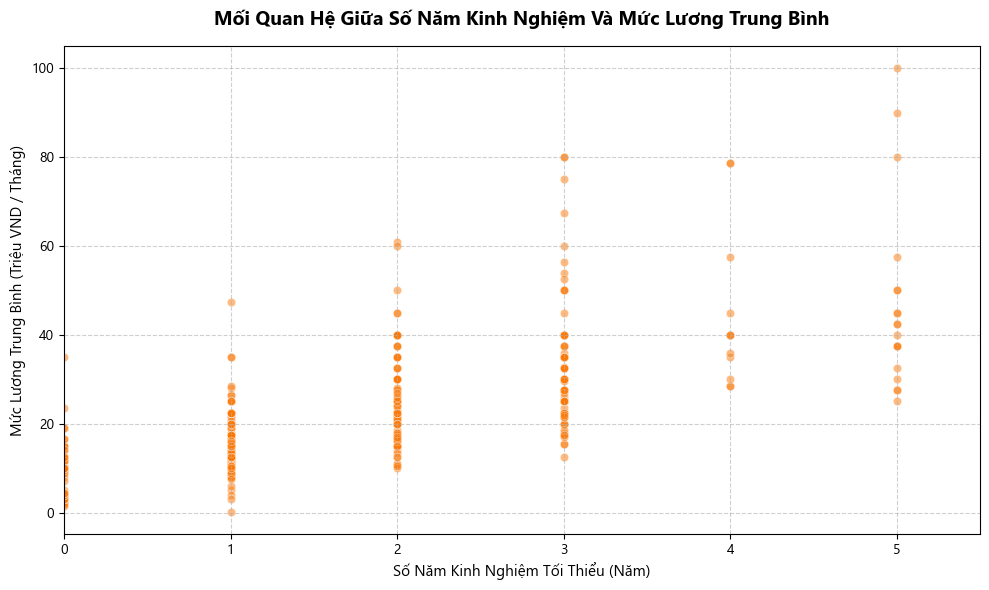

In [25]:
# 1. Cấu hình để vẽ biểu đồ hiển thị đúng font tiếng Việt không bị lỗi ô vuông
plt.rcParams['font.family'] = 'Segoe UI' # Hoặc 'Arial', 'Tahoma' tùy máy em
plt.figure(figsize=(10, 6))

# 2. Loại bỏ các dòng bị Null ở cả 2 cột để tránh lỗi đồ thị
df_plot = df.dropna(subset=['mean_salary', 'experience'])

# Mẹo quy đổi mức lương sang đơn vị "Triệu VND" cho trục tọa độ ngắn gọn, dễ nhìn
df_plot['mean_salary_million'] = df_plot['mean_salary'] / 1000000


# 3. Vẽ b
sns.scatterplot(
    data=df_plot, 
    x='experience', 
    y='mean_salary_million', 
    alpha=0.5, # Độ trong suốt để nhìn rõ những chỗ các chấm đè lên nhau
    color="#ff7700"
)


# 4. Trang trí biểu đồ chuẩn phong cách báo cáo khoa học
plt.title('Mối Quan Hệ Giữa Số Năm Kinh Nghiệm Và Mức Lương Trung Bình', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Số Năm Kinh Nghiệm Tối Thiểu (Năm)', fontsize=11)
plt.ylabel('Mức Lương Trung Bình (Triệu VND / Tháng)', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6) # Thêm lưới mờ cho dễ dóng hàng

# Thới hạn hiển thị trục X gọn gàng từ 0 đến tối đa số năm kinh nghiệm thực tế trong data
plt.xlim(0, df_plot['experience'].max() + 0.5)

# 5. Hiển thị biểu đồ
plt.tight_layout()
plt.show()


C:\Users\HAN NGA\AppData\Local\Temp\ipykernel_19332\1035102999.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_plot['mean_salary_million'] = df_plot['mean_salary'] / 1000000


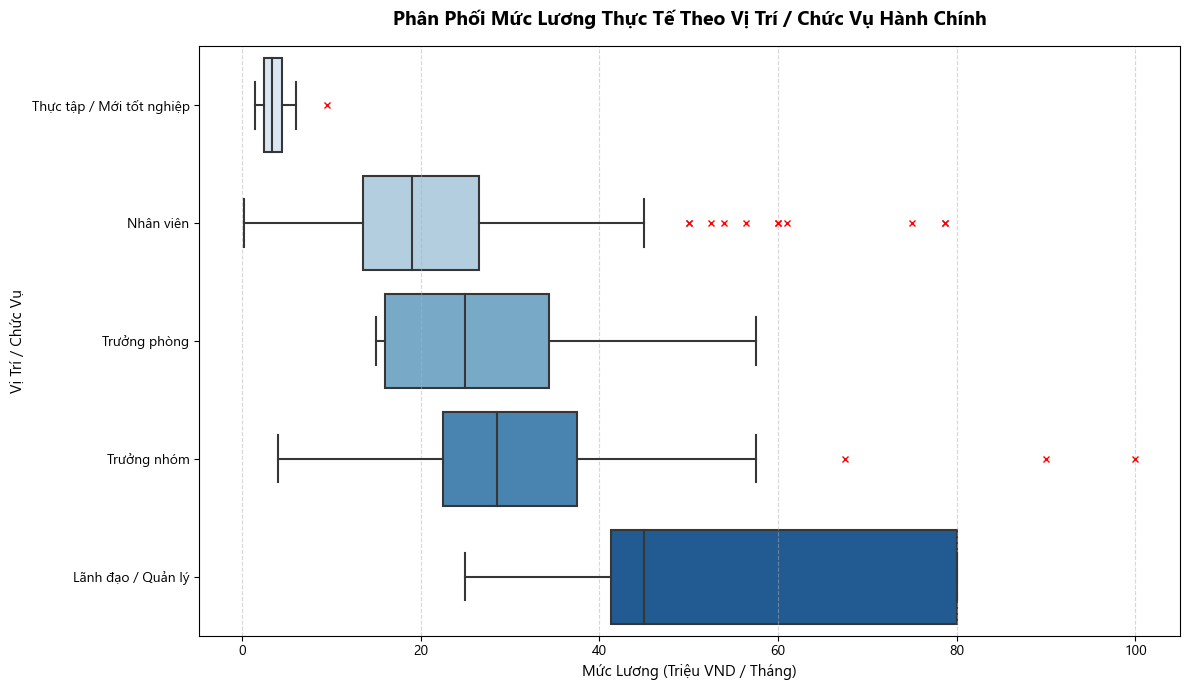

In [26]:
# LƯƠNG VÀ CHỨC VỊ

# 1. Cấu hình hiển thị đúng font tiếng Việt không bị lỗi ô vuông
plt.rcParams['font.family'] = 'Segoe UI'  # Hoặc 'Arial', 'Tahoma'
plt.figure(figsize=(12, 7))

# 2. Dọn dẹp dữ liệu trống (Null) trước khi vẽ
df_plot = df.dropna(subset=['mean_salary', 'job_position'])

# Quy đổi đơn vị lương sang "Triệu VND" cho trục tọa độ tinh tế, sạch sẽ
df_plot['mean_salary_million'] = df_plot['mean_salary'] / 1000000

# Tự động tính trung vị (Median) lương để sắp xếp thứ tự các chức vụ từ thấp đến cao
order_positions = df_plot.groupby('job_position')['mean_salary_million'].median().sort_values().index

# 3. Vẽ biểu đồ Boxplot ngang
# Thuộc tính flierprops dùng để làm đẹp các chấm lương đột biến (Outliers)
sns.boxplot(
    data=df_plot,
    x='mean_salary_million',
    y='job_position',
    order=order_positions,
    palette='Blues',  # Hệ màu xanh dương chuyển sắc theo cấp bậc nhân sự
    flierprops={"marker": "x", "markerfacecolor": "red", "markeredgecolor": "red", "markersize": 5} # Outliers màu đỏ gạch chéo
)

# 4. Trang trí biểu đồ chuẩn phong cách báo cáo khoa học xuất sắc
plt.title('Phân Phối Mức Lương Thực Tế Theo Vị Trí / Chức Vụ Hành Chính', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Mức Lương (Triệu VND / Tháng)', fontsize=11)
plt.ylabel('Vị Trí / Chức Vụ', fontsize=11)
plt.grid(axis='x', linestyle='--', alpha=0.5)  # Lưới dọc mờ để dễ dóng hàng tiền

# 5. Hiển thị biểu đồ
plt.tight_layout()
plt.show()


## 2.7. deadline_date DATE TIME

In [28]:
df['deadline_date'].head(5)

0    13/05/2026
1    30/06/2026
2    30/06/2026
3    08/05/2026
4    07/05/2026
Name: deadline_date, dtype: object

In [29]:
# 1. Chuyển đổi cột 'date_post' sang kiểu datetime (nếu chưa có)
df['deadline_date'] = pd.to_datetime(df['deadline_date'])
df['deadline_date'].head(5)

C:\Users\HAN NGA\AppData\Local\Temp\ipykernel_19332\2696961036.py:2: UserWarning: Parsing dates in %d/%m/%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df['deadline_date'] = pd.to_datetime(df['deadline_date'])


0   2026-05-13
1   2026-06-30
2   2026-06-30
3   2026-05-08
4   2026-05-07
Name: deadline_date, dtype: datetime64[ns]

In [31]:
# Chuyển đổi trực tiếp 2 cột từ datetime sang chỉ lấy phần ngày (date)
df['deadline_date'] = df['deadline_date'].dt.date

df['deadline_date'].value_counts().head(10)

deadline_date
2026-06-30    48
2026-05-31    46
2026-04-30    40
2026-07-31    21
2026-05-13    17
2026-05-16    16
2026-06-06    16
2026-06-20    16
2026-07-03    15
2026-05-02    14
Name: count, dtype: int64

In [32]:
# Xóa cột phụ nếu không cần thiết nữa
df = df.drop(columns=['test', 'co_hien_thi_luong', 'loai_tien_te', 'viet_tat_trieu', 'tinh_theo_nam', 
                      'salary_min', 'salary_max', 'mean_salary_no_unit',
                      'education'])

In [33]:
## 2. SAVED lần 4
df.to_csv("data_topcv_4.csv", index=False, encoding="utf-8-sig")